# EduPredict – Student Career Path Prediction

This notebook trains and evaluates a **multiclass classification** model for the EduPredict career-path module. It follows the general workflow used in the existing EduPredict classification notebooks: dataset preparation, stratified train/test split, algorithm comparison with stratified cross-validation, held-out evaluation, confusion matrix, model export, and a sample prediction.

**Target:** `Recommended Career Domain`

**Model-selection metric:** Macro F1-score. This gives each career domain equal weight, which is important because the seven target classes are imbalanced.

> **Dataset limitations:** The 500-row CSV is adapted from another dataset. Its career-domain target is mapped from suggested job-role labels. Project Count, Project Focus, and Internship were generated during dataset preparation, and CGPA is an estimated value calculated from available academic percentages rather than an official recorded CGPA. Results measure how well a model learns this prepared dataset; they do not establish real-world career-guidance accuracy. Use consent-based student data and independently reviewed career labels before real deployment.

## 1. Install dependencies

Run this cell only if the required packages are not already installed. XGBoost is optional; the notebook will skip it if it is unavailable.

In [ ]:
# Uncomment and run if packages are missing:
# %pip install pandas numpy scikit-learn matplotlib joblib
# %pip install xgboost  # Optional model

## 2. Imports and configuration

In [7]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

# Keep the CSV in the same folder as this notebook, or edit this path.
DATASET_PATH = Path("edupredict_career_path_500_revised.csv")

# Output files will be written into this folder.
OUTPUT_DIR = Path("edupredict_model_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Dataset path:", DATASET_PATH.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Working directory: /content
Dataset path: /content/edupredict_career_path_500_revised.csv
Output directory: /content/edupredict_model_outputs


## 3. Load and validate the dataset

Only the agreed 11 input columns and the target column are retained. Any ID or unrelated columns are excluded. Missing feature values can be imputed inside the training pipeline; rows without a target label cannot be used for supervised training.

In [8]:
TARGET = "Recommended Career Domain"

NUMERIC_FEATURES = [
    "CGPA (out of 10)",
    "Coding Rating",
    "Public Speaking Rating",
    "Mathematics (%)",
    "Project Count",
]

CATEGORICAL_FEATURES = [
    "Interested Subjects",
    "Career Area",
    "Can Work Long",
    "Project Focus",
    "Internship",
    "Career Preference",
]

FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
REQUIRED_COLUMNS = FEATURE_COLUMNS + [TARGET]

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATASET_PATH}. Place the CSV beside this notebook "
        "or update DATASET_PATH in the configuration cell."
    )

raw_df = pd.read_csv(DATASET_PATH)
raw_df.columns = raw_df.columns.astype(str).str.strip()

missing_columns = [col for col in REQUIRED_COLUMNS if col not in raw_df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Retain only the defined features and target, in a predictable order.
df = raw_df[REQUIRED_COLUMNS].copy()

# Convert numerical features safely. Invalid numeric strings become missing values
# and will be handled by the numeric imputer fitted on each training fold.
for column in NUMERIC_FEATURES:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Clean categorical fields while preserving missing values for imputation.
for column in CATEGORICAL_FEATURES:
    values = df[column].astype("string").str.strip()
    values = values.mask(values.eq(""), pd.NA)
    df[column] = values.astype(object)

# Remove rows without a known target.
df[TARGET] = df[TARGET].astype("string").str.strip()
df[TARGET] = df[TARGET].mask(df[TARGET].eq(""), pd.NA)
rows_before = len(df)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Rows removed because target was missing: {rows_before - len(df)}")

# Validate common numeric ranges in this dataset.
range_checks = {
    "CGPA (out of 10)": (0, 10),
    "Coding Rating": (1, 10),
    "Public Speaking Rating": (1, 10),
    "Mathematics (%)": (0, 100),
}
for column, (lower, upper) in range_checks.items():
    invalid = df[column].dropna().loc[
        ~df[column].dropna().between(lower, upper)
    ]
    if not invalid.empty:
        raise ValueError(
            f"{column} contains values outside {lower}–{upper}: "
            f"{invalid.head().tolist()}"
        )

if (df["Project Count"].dropna() < 0).any():
    raise ValueError("Project Count cannot contain negative values.")

# Avoid exact duplicate rows being counted more than once.
duplicate_count = int(df.duplicated().sum())
if duplicate_count:
    df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after validation:", df.shape)
print("Exact duplicate rows removed:", duplicate_count)
print("Number of career domains:", df[TARGET].nunique())
print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))
print("\nPreview:")
display(df.head())

Rows removed because target was missing: 0
Dataset shape after validation: (500, 12)
Exact duplicate rows removed: 0
Number of career domains: 7

Missing values by column:


,Missing values
CGPA (out of 10),0
Coding Rating,0
Public Speaking Rating,0
Mathematics (%),0
Project Count,0
Interested Subjects,0
Career Area,0
Can Work Long,0
Project Focus,0
Internship,0



Preview:


,CGPA (out of 10),Coding Rating,Public Speaking Rating,Mathematics (%),Project Count,Interested Subjects,Career Area,Can Work Long,Project Focus,Internship,Career Preference,Recommended Career Domain
0,7.84,7,4,88,0,IoT,System Developer,Yes,IoT; Data Science,No,Higher Studies,Business & IT Management
1,7.99,6,1,83,2,Parallel Computing,Business Process Analyst,Yes,Parallel Computing; System Designing,No,Higher Studies,Cybersecurity & Networking
2,7.40,4,6,78,1,Software Engineering,System Developer,Yes,Software Engineering; Testing,No,Job,Business & IT Management
3,7.89,4,1,81,1,Programming,Cloud Computing,Yes,Programming; Web Technologies,No,Higher Studies,Cybersecurity & Networking
4,7.93,7,9,72,3,Hacking,Developer,No,Hacking; System Designing,No,Job,Data & Database Systems


## 4. Explore target distribution

Check the number of examples available for each career domain before splitting. The smallest class must have at least five rows to support five-fold stratified cross-validation.

,Records,Percentage
Recommended Career Domain,,
Software & Application Development,113,22.6
Cybersecurity & Networking,87,17.4
Business & IT Management,87,17.4
Data & Database Systems,85,17.0
Cloud & IT Infrastructure,71,14.2
UI/UX & Product Design,29,5.8
Quality Assurance & Testing,28,5.6


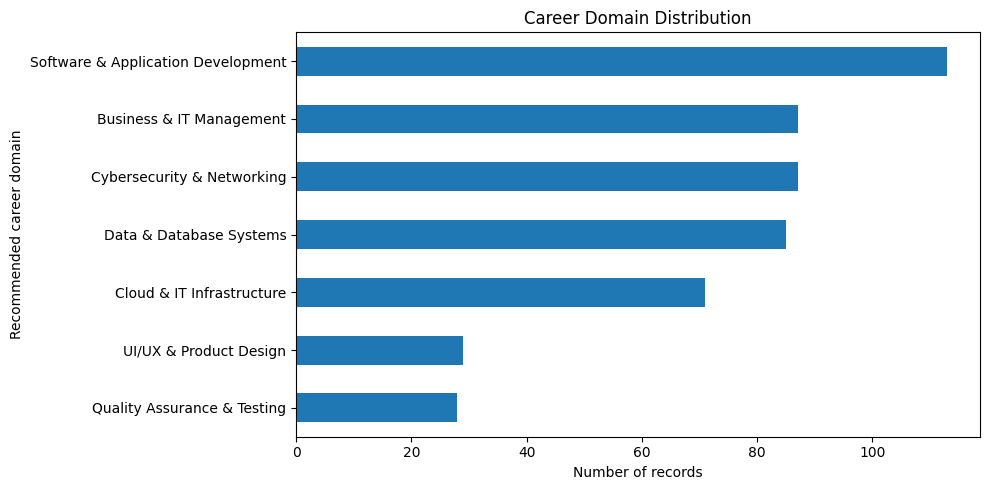

Smallest class count: 28
Cross-validation folds: 5


In [9]:
class_counts = df[TARGET].value_counts().sort_values(ascending=False)
class_percentages = (df[TARGET].value_counts(normalize=True) * 100).reindex(class_counts.index)

target_summary = pd.DataFrame({
    "Records": class_counts,
    "Percentage": class_percentages.round(2),
})
display(target_summary)

ax = class_counts.sort_values().plot(kind="barh", figsize=(10, 5))
ax.set_title("Career Domain Distribution")
ax.set_xlabel("Number of records")
ax.set_ylabel("Recommended career domain")
plt.tight_layout()
plt.show()

minimum_class_count = int(class_counts.min())
if minimum_class_count < N_SPLITS:
    raise ValueError(
        f"The smallest class has only {minimum_class_count} rows. "
        f"Reduce N_SPLITS to at most {minimum_class_count} or collect more data."
    )

print("Smallest class count:", minimum_class_count)
print("Cross-validation folds:", N_SPLITS)

## 5. Separate input features and target

The model receives all 11 agreed input fields. The target is the recommended career domain. No record identifier is used as a feature.

In [10]:
X = df[FEATURE_COLUMNS].copy()
y_text = df[TARGET].astype(str).copy()

# Encode target labels as integers. This also keeps the target compatible with
# XGBoost versions that require consecutive integer class labels.
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_text)

print("Input feature count:", X.shape[1])
print("Input columns:", FEATURE_COLUMNS)
print("Target name:", TARGET)
print("Target label mapping:")
display(pd.DataFrame({"Encoded label": range(len(target_encoder.classes_)), "Career domain": target_encoder.classes_}))

Input feature count: 11
Input columns: ['CGPA (out of 10)', 'Coding Rating', 'Public Speaking Rating', 'Mathematics (%)', 'Project Count', 'Interested Subjects', 'Career Area', 'Can Work Long', 'Project Focus', 'Internship', 'Career Preference']
Target name: Recommended Career Domain
Target label mapping:


,Encoded label,Career domain
0,0,Business & IT Management
1,1,Cloud & IT Infrastructure
2,2,Cybersecurity & Networking
3,3,Data & Database Systems
4,4,Quality Assurance & Testing
5,5,Software & Application Development
6,6,UI/UX & Product Design


## 6. Train/test split

A stratified 80/20 split keeps the career-domain proportions approximately consistent. The test set is held back and is not used for algorithm selection.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nTraining class distribution:")
train_distribution = pd.Series(target_encoder.inverse_transform(y_train)).value_counts().to_frame("Training records")
display(train_distribution)
print("\nTesting class distribution:")
test_distribution = pd.Series(target_encoder.inverse_transform(y_test)).value_counts().to_frame("Testing records")
display(test_distribution)

Training records: 400
Testing records: 100

Training class distribution:


,Training records
Software & Application Development,90
Cybersecurity & Networking,70
Business & IT Management,70
Data & Database Systems,68
Cloud & IT Infrastructure,57
UI/UX & Product Design,23
Quality Assurance & Testing,22



Testing class distribution:


,Testing records
Software & Application Development,23
Data & Database Systems,17
Cybersecurity & Networking,17
Business & IT Management,17
Cloud & IT Infrastructure,14
UI/UX & Product Design,6
Quality Assurance & Testing,6


## 7. Build preprocessing pipeline

Numerical features are median-imputed and standardized. Categorical features are most-frequent-imputed and one-hot encoded. `handle_unknown='ignore'` allows the saved pipeline to accept a category that was not present during training.

Preprocessing is inside each model pipeline, so imputers, scalers, and encoders are fitted separately within each cross-validation training fold. This prevents preprocessing leakage.

In [12]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Support both newer and older scikit-learn versions. Dense output is used so
# Gaussian Naive Bayes can be compared in the same preprocessing workflow.
try:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot_encoder),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, NUMERIC_FEATURES),
        ("categorical", categorical_preprocessor, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


## 8. Define classification algorithms

The candidates include Random Forest, Extra Trees, SVM, KNN, Gaussian Naive Bayes, Logistic Regression, Decision Tree, and XGBoost when installed. Class-weight balancing is enabled where supported. All candidates use the same preprocessing pipeline and validation folds.

In [13]:
classifiers = {
    "Majority Class Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
    ),
    "Support Vector Machine (RBF)": SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "Gaussian Naive Bayes": GaussianNB(),
}

# XGBoost is optional. It is added only when the package is available.
try:
    from xgboost import XGBClassifier

    classifiers["XGBoost"] = XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_estimators=250,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )
    print("XGBoost is available and will be evaluated.")
except ImportError:
    print("XGBoost is not installed; skipping it. Install with: %pip install xgboost")

print("\nModels to compare:")
for model_name in classifiers:
    print("-", model_name)

XGBoost is available and will be evaluated.

Models to compare:
- Majority Class Baseline
- Logistic Regression
- K-Nearest Neighbors
- Support Vector Machine (RBF)
- Decision Tree
- Random Forest
- Extra Trees
- Gaussian Naive Bayes
- XGBoost


## 9. Compare models using 5-fold stratified cross-validation

Models are ranked by **mean macro F1-score** on the training split only. Accuracy, balanced accuracy, macro precision, and macro recall are also reported. The held-out test set is not used to choose the model.

In [14]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}

comparison_rows = []
cv_details = {}

for model_name, classifier in classifiers.items():
    print(f"Evaluating: {model_name}")
    candidate_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier)),
    ])

    scores = cross_validate(
        candidate_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
    )
    cv_details[model_name] = scores

    comparison_rows.append({
        "Model": model_name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Mean CV Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Mean CV Precision (Macro)": scores["test_precision_macro"].mean(),
        "Mean CV Recall (Macro)": scores["test_recall_macro"].mean(),
        "Mean CV F1 (Macro)": scores["test_f1_macro"].mean(),
        "Std CV F1 (Macro)": scores["test_f1_macro"].std(),
    })

results_df = (
    pd.DataFrame(comparison_rows)
    .sort_values(
        by=["Mean CV F1 (Macro)", "Mean CV Balanced Accuracy"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

print("\nCareer Path Classification – 5-Fold CV Comparison")
print("=" * 62)
display(results_df.round(4))

best_model_name = results_df.loc[0, "Model"]
best_classifier = classifiers[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: highest mean CV Macro F1-score")
print("Best mean CV Macro F1:", round(results_df.loc[0, "Mean CV F1 (Macro)"], 4))

Evaluating: Majority Class Baseline
Evaluating: Logistic Regression
Evaluating: K-Nearest Neighbors
Evaluating: Support Vector Machine (RBF)
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: Extra Trees
Evaluating: Gaussian Naive Bayes
Evaluating: XGBoost

Career Path Classification – 5-Fold CV Comparison


,Model,Mean CV Accuracy,Mean CV Balanced Accuracy,Mean CV Precision (Macro),Mean CV Recall (Macro),Mean CV F1 (Macro),Std CV F1 (Macro)
0,Logistic Regression,0.1650,0.1875,0.1621,0.1875,0.1663,0.0515
1,Extra Trees,0.1625,0.1651,0.1553,0.1651,0.1533,0.0381
2,Support Vector Machine (RBF),0.1675,0.1609,0.1516,0.1609,0.1529,0.0472
3,Random Forest,0.1700,0.1463,0.1409,0.1463,0.1420,0.0355
4,Gaussian Naive Bayes,0.1575,0.1950,0.1698,0.1950,0.1415,0.0168
5,XGBoost,0.1625,0.1303,0.1452,0.1303,0.1290,0.0257
6,K-Nearest Neighbors,0.1700,0.1341,0.1260,0.1341,0.1269,0.0157
7,Decision Tree,0.1475,0.1616,0.0930,0.1616,0.0815,0.0201
8,Majority Class Baseline,0.2250,0.1429,0.0321,0.1429,0.0525,0.0000


Selected model: Logistic Regression
Selection criterion: highest mean CV Macro F1-score
Best mean CV Macro F1: 0.1663


## 10. Fit the selected model on the complete training split

After selecting the algorithm using cross-validation, fit its complete preprocessing-and-model pipeline on all training records.

In [15]:
career_path_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", clone(best_classifier)),
])

career_path_model.fit(X_train, y_train)
print(f"{best_model_name} trained successfully.")

Logistic Regression trained successfully.


## 11. Evaluate on the held-out test set

These metrics are calculated once on the 20% test set that was not used for model selection. Review the per-class precision, recall, and F1-score, especially for the smaller domains.

In [16]:
y_pred = career_path_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

# Compare against a simple majority-class baseline. A trained model should
# provide useful improvement over this baseline, especially on Macro F1.
majority_baseline = DummyClassifier(strategy="most_frequent")
majority_baseline.fit(X_train, y_train)
baseline_pred = majority_baseline.predict(X_test)

evaluation_comparison = pd.DataFrame([
    {
        "Model": best_model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    },
    {
        "Model": "Majority Class Baseline",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, baseline_pred),
        "Macro F1": f1_score(y_test, baseline_pred, average="macro", zero_division=0),
    },
])

print("Selected model:", best_model_name)
print("\nHeld-out test results")
print("---------------------")
print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Macro F1-score:    {test_macro_f1:.4f}")
display(evaluation_comparison.round(4))

y_test_labels = target_encoder.inverse_transform(y_test)
y_pred_labels = target_encoder.inverse_transform(y_pred)

print("\nClassification Report:")
print(classification_report(
    y_test_labels,
    y_pred_labels,
    labels=target_encoder.classes_,
    target_names=target_encoder.classes_,
    zero_division=0,
))

Selected model: Logistic Regression

Held-out test results
---------------------
Accuracy:          0.1300
Balanced Accuracy: 0.1507
Macro F1-score:    0.1312


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Logistic Regression,0.13,0.1507,0.1312
1,Majority Class Baseline,0.23,0.1429,0.0534



Classification Report:
                                    precision    recall  f1-score   support

          Business & IT Management       0.18      0.18      0.18        17
         Cloud & IT Infrastructure       0.10      0.07      0.08        14
        Cybersecurity & Networking       0.17      0.12      0.14        17
           Data & Database Systems       0.06      0.06      0.06        17
       Quality Assurance & Testing       0.15      0.33      0.21         6
Software & Application Development       0.20      0.13      0.16        23
            UI/UX & Product Design       0.07      0.17      0.10         6

                          accuracy                           0.13       100
                         macro avg       0.13      0.15      0.13       100
                      weighted avg       0.14      0.13      0.13       100



## 12. Confusion matrix

Rows represent actual career domains; columns represent predicted domains. Off-diagonal values show where the model confuses one domain with another.

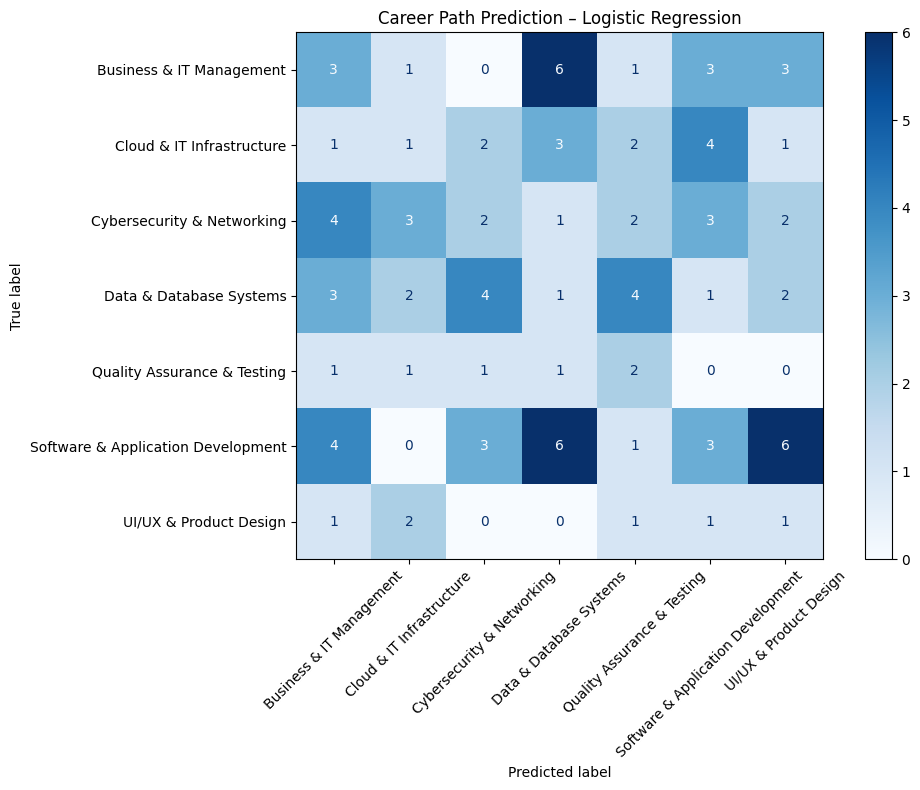

In [17]:
class_labels = target_encoder.classes_

fig, ax = plt.subplots(figsize=(11, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test_labels,
    y_pred_labels,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax,
)
ax.set_title(f"Career Path Prediction – {best_model_name}")
plt.tight_layout()
plt.show()

## 13. Inspect feature importance when supported

Tree-based models expose impurity-based feature importance. The values refer to the encoded features created by the preprocessing pipeline, so one original categorical field can appear as several encoded features. This section is skipped for models without `feature_importances_`.

In [18]:
fitted_classifier = career_path_model.named_steps["classifier"]
fitted_preprocessor = career_path_model.named_steps["preprocessor"]

if hasattr(fitted_classifier, "feature_importances_"):
    transformed_feature_names = fitted_preprocessor.get_feature_names_out()
    importance_values = fitted_classifier.feature_importances_

    feature_importance_df = (
        pd.DataFrame({
            "Feature": transformed_feature_names,
            "Importance": importance_values,
        })
        .sort_values("Importance", ascending=False)
        .reset_index(drop=True)
    )
    display(feature_importance_df.head(20))

    top_features = feature_importance_df.head(15).sort_values("Importance")
    ax = top_features.plot(
        x="Feature",
        y="Importance",
        kind="barh",
        legend=False,
        figsize=(10, 7),
    )
    ax.set_title("Top Encoded Feature Importances")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Encoded feature")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_model_name} does not expose feature_importances_.")

Logistic Regression does not expose feature_importances_.


## 14. Save the trained model and comparison results

The `.pkl` file contains the complete fitted pipeline, including imputers, scaling, one-hot encoding, and the classifier. Use the same feature names and column order when calling `predict()` from the EduPredict backend.

In [19]:
model_path = OUTPUT_DIR / "career_path_prediction_model.pkl"
target_encoder_path = OUTPUT_DIR / "career_path_target_encoder.pkl"
comparison_path = OUTPUT_DIR / "career_path_model_comparison.csv"
metadata_path = OUTPUT_DIR / "career_path_model_metadata.json"

joblib.dump(career_path_model, model_path)
joblib.dump(target_encoder, target_encoder_path)
results_df.to_csv(comparison_path, index=False)

metadata = {
    "model_name": best_model_name,
    "target_column": TARGET,
    "feature_columns": FEATURE_COLUMNS,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "classes": [str(value) for value in target_encoder.classes_],
    "target_encoder_file": target_encoder_path.name,
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "cross_validation_folds": int(N_SPLITS),
    "selection_metric": "mean CV Macro F1-score",
    "best_mean_cv_macro_f1": float(results_df.loc[0, "Mean CV F1 (Macro)" ]),
    "held_out_test_accuracy": float(test_accuracy),
    "held_out_test_balanced_accuracy": float(test_balanced_accuracy),
    "held_out_test_macro_f1": float(test_macro_f1),
    "random_state": RANDOM_STATE,
}
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Best model:", best_model_name)
print("Saved model:", model_path.resolve())
print("Saved target encoder:", target_encoder_path.resolve())
print("Saved comparison:", comparison_path.resolve())
print("Saved metadata:", metadata_path.resolve())

Best model: Logistic Regression
Saved model: /content/edupredict_model_outputs/career_path_prediction_model.pkl
Saved target encoder: /content/edupredict_model_outputs/career_path_target_encoder.pkl
Saved comparison: /content/edupredict_model_outputs/career_path_model_comparison.csv
Saved metadata: /content/edupredict_model_outputs/career_path_model_metadata.json


## 15. Example prediction for a new student

Replace the example values with a student's actual responses. Categorical values not seen during training are accepted by the encoder, but predictions for unfamiliar profiles may be unreliable. Model probability outputs are estimated class probabilities, not guarantees of career suitability.

In [20]:
new_student = pd.DataFrame([{
    "CGPA (out of 10)": 8.4,
    "Coding Rating": 8,
    "Public Speaking Rating": 6,
    "Interested Subjects": "Programming",
    "Career Area": "Developer",
    "Can Work Long": "Yes",
    "Mathematics (%)": 85,
    "Project Count": 3,
    "Project Focus": "Programming; Web Technologies",
    "Internship": "Yes",
    "Career Preference": "Job",
}], columns=FEATURE_COLUMNS)

predicted_encoded_label = career_path_model.predict(new_student)[0]
predicted_domain = target_encoder.inverse_transform([predicted_encoded_label])[0]
print("Recommended career domain:", predicted_domain)

if hasattr(career_path_model, "predict_proba"):
    probabilities = career_path_model.predict_proba(new_student)[0]
    decoded_classes = target_encoder.inverse_transform(career_path_model.classes_.astype(int))
    probability_table = (
        pd.DataFrame({
            "Career Domain": decoded_classes,
            "Estimated Probability": probabilities,
        })
        .sort_values("Estimated Probability", ascending=False)
        .reset_index(drop=True)
    )
    probability_table["Estimated Probability"] = (
        probability_table["Estimated Probability"] * 100
    ).round(2)
    display(probability_table)

Recommended career domain: Cloud & IT Infrastructure


,Career Domain,Estimated Probability
0,Cloud & IT Infrastructure,33.43
1,Data & Database Systems,16.87
2,Cybersecurity & Networking,14.35
3,Software & Application Development,10.96
4,Quality Assurance & Testing,9.86
5,UI/UX & Product Design,9.74
6,Business & IT Management,4.80
